# P-1-1: source-row repair and connection review

Compare the frozen October 31 baseline with `id_row_mapping_20261102_r1`.
Only adapter source-row assignment changes. All seven inherited lambda values
remain visible; none is selected. Agreement is with reviewed labels on shared
geometry, not independently certified 3D accuracy or generalization to other fish.

In [1]:
import json
import sys
import tomllib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import medaka3d
from medaka3d import load_paths

matplotlib.use("module://matplotlib_inline.backend_inline")
repo = Path(medaka3d.__file__).resolve().parents[2]
assert Path(sys.prefix).resolve() == (repo / ".venv").resolve()
analysis = repo / "analyses/20261031_p11_identity_evaluation"
config = tomllib.loads((analysis / "config_row_mapping_v1.toml").read_text())
root = load_paths().raw_data_dir.parent / config["output"]["relative_to_data_parent"]
repair = root / config["run_id"]
baseline = root / config["comparison"]["baseline_run"]
assert json.loads((repair / "run_status.json").read_text())["status"] == "complete"
scoring_name = config["evaluation"]["primary_scoring_directory"]
validation = json.loads((repair / scoring_name / "validation.json").read_text())
assert validation["summary_reconciled"]
assert all(v["discrepancies"] == 0 for v in validation["arms"].values())
shown = config["evaluation"]["display_lambda"]
figure_dir = repair / "repair_figures"
figure_dir.mkdir(exist_ok=True)
runs = {"Baseline": baseline, "Repair": repair}
primary = {}
for name, run in runs.items():
    table = pd.read_csv(run / scoring_name / "identity_summary.csv")
    primary[name] = table[table.match_distance_mm.eq(
        config["evaluation"]["max_match_distance_mm"]
    )].copy()
print("Recording:", config["experiment"])
print("Baseline:", baseline.name, "| Repair:", repair.name)
print("Independent scalar checks:", sum(v["independent_exact_coordinate_checks"]
                                          for v in validation["arms"].values()))

Recording: 20260112_P_1_1_FCMC
Baseline: id_evaluation_20261031_r2 | Repair: id_row_mapping_20261102_r1
Independent scalar checks: 19087


## Whole-window identity agreement

The fixed pre-window anchor is never refitted after a crossing. Report the
scored denominator with agreement, and preserve missing time in the complete
expected fish-time denominator. Slot renaming is aligned once by those same anchors.

In [2]:
overview = []
for name, table in primary.items():
    for lam, rows in table.groupby("lambda_mm"):
        correct, wrong = rows.correct_id_seconds.sum(), rows.wrong_id_seconds.sum()
        expected = rows.expected_seconds.sum()
        overview.append({
            "Run": name, "Lambda": lam,
            "Agreement on scored time (%)": 100 * correct / (correct + wrong),
            "Scored / expected (%)": 100 * (correct + wrong) / expected,
            "Correct / expected (%)": 100 * correct / expected,
        })
overview = pd.DataFrame(overview)
display(overview.round(4))
comparison = pd.DataFrame({
    float(lam): {
        "Changed matched identity (fish-s)": row["changed_identity_fish_seconds_both_matched"],
        "Changed scoring status (rows)": row["changed_score_status_observations"],
        "Maximum aligned XYZ difference (mm)": row["post_preparation_fields"]["xyz"][
            "max_absolute_difference"
        ],
    } for lam, row in validation["anchor_aligned_comparison"].items()
}).T.sort_index()
comparison.index.name = "Lambda"
display(comparison)
display(pd.DataFrame(validation["c27_previous_comparison"]).T[
    ["different_labels", "unique_labels"]
])
individual = pd.concat([
    rows[rows.lambda_mm.eq(shown)].assign(run=name)
    for name, rows in primary.items()
])
display(individual[["run", "reference_label", "id_agreement_on_scored_time",
    "wrong_id_seconds", "scored_time_fraction", "correct_run_max_seconds"]].round(4))

,Run,Lambda,Agreement on scored time (%),Scored / expected (%),Correct / expected (%)
0,Baseline,0.000,38.7304,98.8737,38.2942
1,Baseline,0.100,27.2693,98.8626,26.9591
2,Baseline,0.250,49.8312,98.8617,49.2639
3,Baseline,0.500,45.0228,98.8552,44.5073
4,Baseline,0.767,84.1084,98.8514,83.1423
5,Baseline,2.000,19.7172,98.8360,19.4877
6,Baseline,8.000,22.5237,98.7892,22.2509
7,Repair,0.000,38.7304,98.8737,38.2942
8,Repair,0.100,27.2693,98.8626,26.9591
9,Repair,0.250,49.8312,98.8617,49.2639


,Changed matched identity (fish-s),Changed scoring status (rows),Maximum aligned XYZ difference (mm)
Lambda,,,
0.000,0.0,0.0,0.0
0.100,0.0,0.0,0.0
0.250,0.0,0.0,0.0
0.500,0.0,0.0,0.0
0.767,0.0,0.0,0.0
2.000,0.0,0.0,0.0
8.000,0.0,0.0,0.0


,different_labels,unique_labels
top_cam,2,6
side1_cam,0,6
side2_cam,0,6


,run,reference_label,id_agreement_on_scored_time,wrong_id_seconds,scored_time_fraction,correct_run_max_seconds
39,Baseline,F,0.9878,21.6354,0.9818,94.6329
40,Baseline,M1,0.7635,419.8497,0.9863,78.1186
41,Baseline,M2,0.7734,406.9323,0.9975,116.9249
39,Repair,F,0.9878,21.6354,0.9818,94.6329
40,Repair,M1,0.7635,419.8497,0.9863,78.1186
41,Repair,M2,0.7734,406.9323,0.9975,116.9249


## Connection evidence and unassessed scope

These are same-slot segment edges, not swap events. Both track and segment
labels require 100 matched frames, 0.5 matched seconds, 95% matched duration,
and no positive-duration minority label. A gap's endpoints may support a
connection; the interior remains unassessed. The temporal candidate groups
are unreviewed and do not establish independent encounters.
Edge boundaries and assessable subsets differ across lambda settings, so
these counts are not a matched-event ranking of the seven settings.

,Run,Lambda,correct,wrong,undecidable,All edges,Assessed / all edges (%),Temporal review groups
0,Baseline,0.000,54,23,1491,1568,4.911,332
1,Baseline,0.100,67,6,1110,1183,6.171,290
2,Baseline,0.250,70,4,1056,1130,6.549,283
3,Baseline,0.500,77,3,1108,1188,6.734,301
4,Baseline,0.767,72,2,1147,1221,6.061,302
5,Baseline,2.000,66,2,1207,1275,5.333,305
6,Baseline,8.000,63,1,1361,1425,4.491,329
7,Repair,0.000,54,23,1491,1568,4.911,332
8,Repair,0.100,67,6,1110,1183,6.171,290
9,Repair,0.250,70,4,1056,1130,6.549,283


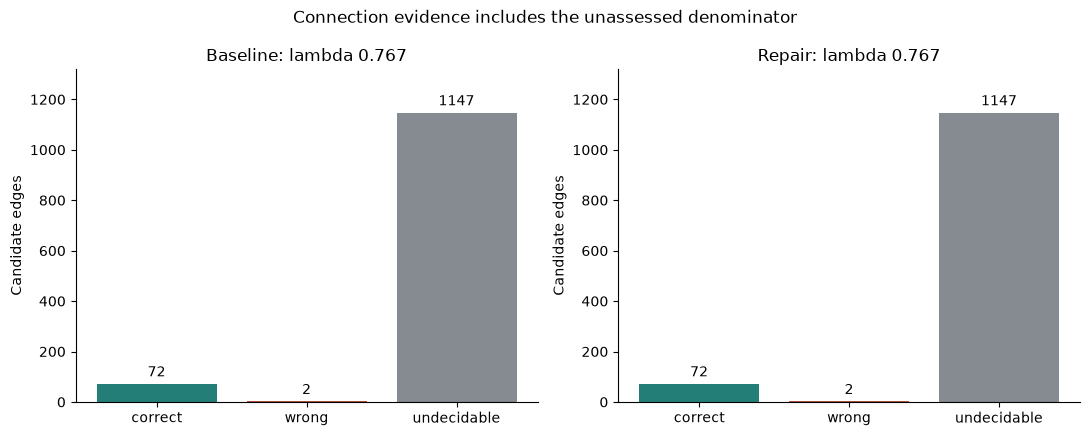

,local_tracks,observed_seconds,matched_seconds
label_status,,,
insufficient_support,291,11.477,8.103
mixed,13,612.591,575.189
reference_incomplete,4,31.733,25.292
supported_reference_label,150,4741.735,4730.179
unassessed,108,1.609,0.000


,track_label_status,correct_fish_seconds,wrong_fish_seconds,run
0,insufficient_support,6.145,1.958,Baseline
1,mixed,516.862,58.327,Baseline
2,reference_incomplete,25.292,0.000,Baseline
3,supported_reference_label,3942.047,788.132,Baseline
4,unassessed,0.000,0.000,Baseline
5,insufficient_support,6.145,1.958,Repair
6,mixed,516.862,58.327,Repair
7,reference_incomplete,25.292,0.000,Repair
8,supported_reference_label,3942.047,788.132,Repair
9,unassessed,0.000,0.000,Repair


All three fish; support-category totals reconcile to the fixed-anchor scoring totals.
A pure local track can still carry the wrong trial-wide name.


In [3]:
ledger_rows = []
ledger_roots = {}
for name, variant in [("Baseline", "baseline"), ("Repair", "repair")]:
    ledger_roots[name] = repair / "join_ledger_v2" / variant
    summaries = json.loads((ledger_roots[name] / "summary.json").read_text())
    for lam, row in summaries.items():
        assert row["c30_replay_matches_saved_permutation_and_decisions"]
        ledger_rows.append({
            "Run": name, "Lambda": float(lam), **row["edge_outcomes"],
            "All edges": row["edge_count"],
            "Assessed / all edges (%)": 100 * row["assessed_fraction_of_all_edges"],
            "Temporal review groups": row["candidate_group_count"],
        })
ledger_table = pd.DataFrame(ledger_rows)
display(ledger_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (name, _path) in zip(axes, ledger_roots.items(), strict=True):
    shown_rows = ledger_table[(ledger_table.Run == name) & ledger_table.Lambda.eq(shown)]
    counts = shown_rows[["correct", "wrong", "undecidable"]].iloc[0]
    bars = ax.bar(counts.index, counts, color=["#247E78", "#B4513C", "#858B91"])
    ax.bar_label(bars, padding=3)
    ax.set(title=f"{name}: lambda {shown:g}", ylabel="Candidate edges",
           ylim=(0, max(counts)*1.15))
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Connection evidence includes the unassessed denominator")
fig.tight_layout()
fig.savefig(figure_dir / "connection_evidence.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)
tracks = pd.read_csv(ledger_roots["Repair"] / f"lam{shown:g}" / "tracks.csv")
display(tracks.groupby("label_status").agg(
    local_tracks=("local_track_id", "size"),
    observed_seconds=("observed_seconds", "sum"),
    matched_seconds=("matched_seconds", "sum"),
).round(3))
support_time = []
for name, ledger_root in ledger_roots.items():
    segments = pd.read_csv(ledger_root / f"lam{shown:g}" / "segments.csv")
    anchors = json.loads((runs[name] / scoring_name / "anchor_mappings.json").read_text())
    mapping = anchors[f"{shown:g}"]["reference_to_slot"]
    assert len(set(mapping)) == 3 and min(mapping) >= 0
    segments["correct_seconds"] = 0.0
    for label, slot in zip(("F", "M1", "M2"), mapping, strict=True):
        mask = segments.raw_slot.eq(slot)
        segments.loc[mask, "correct_seconds"] = segments.loc[mask, f"reference_{label}_seconds"]
    segments["wrong_seconds"] = segments.matched_seconds - segments.correct_seconds
    selected_primary = primary[name][primary[name].lambda_mm.eq(shown)]
    for derived, original in [("correct_seconds", "correct_id_seconds"),
                              ("wrong_seconds", "wrong_id_seconds")]:
        assert abs(segments[derived].sum() - selected_primary[original].sum()) < 1e-6
    grouped = segments.groupby("track_label_status").agg(
        correct_fish_seconds=("correct_seconds", "sum"),
        wrong_fish_seconds=("wrong_seconds", "sum"),
    ).reset_index().assign(run=name)
    support_time.append(grouped)
display(pd.concat(support_time, ignore_index=True).round(3))
print("All three fish; support-category totals reconcile to the fixed-anchor scoring totals.")
print("A pure local track can still carry the wrong trial-wide name.")

## Review examples and C30 decisions

Failed and successful connections both remain available for video review.
The C30 replay matches the stored permutation and decision lists exactly.
Temporal association with a final C34 edge is not causal attribution; the
physical correctness of a velocity proposal has not been adjudicated.

In [4]:
selected = ledger_roots["Repair"] / f"lam{shown:g}"
edges = pd.read_csv(selected / "edges.csv")
display(edges[edges.outcome.eq("wrong")][[
    "edge_id", "raw_slot", "before_frame", "after_frame", "before_time_s", "after_time_s",
    "before_reference_label", "after_reference_label", "gap_interior_identity_status"
]])
decisions = pd.read_csv(selected / "c30_decisions.csv")
display(decisions.groupby(["kind", "decision"], dropna=False).agg(
    candidates=("c30_decision_id", "size"),
    velocity_calls=("velocity_called", "sum"),
    velocity_adoptions=("velocity_adopted", "sum"),
))
changes = pd.read_csv(selected / "observed_assignment_changes.csv")
display(changes.groupby("kind").size().rename("Observed correspondence changes"))
wrong = pd.read_csv(selected / "wrong_identity_intervals.csv")
top = wrong.nlargest(10, "duration_s")
display(top[["reference_label", "start_s", "stop_s", "duration_s"]].round(3))
print("Top ten disagreement rows, combined fish-seconds:", top.duration_s.sum())
print("These overlapping per-fish intervals are not a count of independent crossings.")

,edge_id,raw_slot,before_frame,after_frame,before_time_s,after_time_s,before_reference_label,after_reference_label,gap_interior_identity_status
574,574,1,154837,154838,932.872922,932.878945,M1,M2,no_gap
994,994,2,154837,154838,932.872922,932.878945,M2,M1,no_gap


candidates  velocity_calls  velocity_adoptions
kind     decision                                                     
boundary adopted               202               6                   6
         kept_identity         238               0                   0
         refused                53              28                   0
zone     adopted                 3               3                   3
         kept_identity          27              27                   0
         refused                 8               5                   0

kind
adjacent_change        24
gap_endpoint_change    56
Name: Observed correspondence changes, dtype: int64

,reference_label,start_s,stop_s,duration_s
316,M2,1973.038,2050.464,77.426
293,M2,1040.917,1098.708,57.791
259,M1,2050.470,2098.615,48.145
255,M1,1973.134,2015.321,42.186
285,M2,948.742,988.880,40.138
215,M1,948.754,988.880,40.126
317,M2,2050.476,2083.962,33.486
288,M2,991.025,1021.439,30.414
230,M1,1048.195,1073.319,25.124
239,M1,1102.949,1127.362,24.413


Top ten disagreement rows, combined fish-seconds: 419.2473046774976
These overlapping per-fish intervals are not a count of independent crossings.


## Limits and next step

Short, mixed, unsupported, and unobserved connections remain visible. A high
fraction correct among a small assessed subset is not full-trial accuracy.
Review the source videos before consolidating temporal groups into events
or freezing a train/test split. Events sharing tracklet images must not leak
across that split. Appearance and body length remain separate, unexecuted
comparisons; BORIS alignment and reflection classification are unavailable.

See `ROW_MAPPING_REPAIR.md`, the frozen configurations, stage provenance,
`validation.json`, and the two v2 join-ledger directories for the evidence.